# Training an autoencoder on the MNIST

This code is trains an autoencoder on the MNIST dataset. 

An autoencoder is a type of neural network that aims to reconstruct its input, by first compressing it with an encoder into a latent space. And then reconstructing it using a decoder.

In this script. The autoencoder is composed of these two small networks. An encoder, and a decoder. The encoder takes the input image, compresses it down to 32 features and passes the encoded representation to the decoder, which then reconstructs the input image. The autoencoder is trained by minizing the mean squared error between the reconstructed image and the original image.

In [13]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [14]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

train_dataset = datasets.MNIST(root='./data', train=True, download=False, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [15]:
# Model Structuring

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):
        x = x.view(x.size(0), -1) # flatten 28x28 image into 748 values
        x = self.encoder(x)
        x = self.decoder(x)

        return(x)

Epoch: 1/10 - Loss: 0.6360
Epoch: 2/10 - Loss: 0.5635
Epoch: 3/10 - Loss: 0.5460
Epoch: 4/10 - Loss: 0.5384
Epoch: 5/10 - Loss: 0.5337
Epoch: 6/10 - Loss: 0.5303
Epoch: 7/10 - Loss: 0.5284
Epoch: 8/10 - Loss: 0.5269
Epoch: 9/10 - Loss: 0.5256
Epoch: 10/10 - Loss: 0.5245


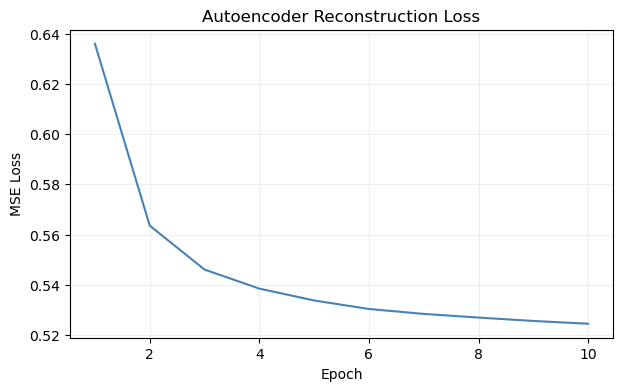

In [18]:
# Training

model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 10


train_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0


    for images, _ in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, images.view(images.size(0), -1))
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    train_losses.append(total_loss / len(train_loader))

    print(f"Epoch: {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")


plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses, color='steelblue')
plt.title('Autoencoder Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True, alpha=0.2)
plt.show()

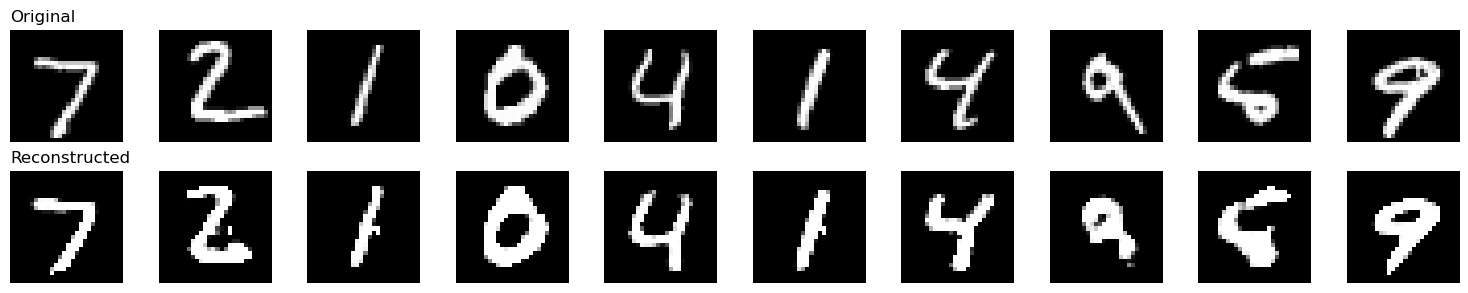

In [20]:
model.eval()

with torch.no_grad():
    sample_images, _ = next(iter(test_loader))
    sample_flat = sample_images.view(sample_images.size(0), -1) # Flatten images
    reconstructed = model(sample_flat)


fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):   
    # Original

    axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')

    # Reconstructed

    axes[1, i].imshow(reconstructed[i].view(28, 28), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_title('Original', loc='left')
axes[1, 0].set_title('Reconstructed', loc='left')

plt.tight_layout()
plt.show()

In [ ]:
# # Model

# class Autoencoder(nn.Module):
#     def __init__(self):
#         super().__init__()

#         # Encoder: Compress 748 - 32

#         # nn.sequential is a container that chains layers together in order. 
#         # Instead of writing each step manually in forward, we package them here and they run one after the other automatically
#         self.encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU())
#         # nn.Linear(784, 128), nn.ReLU() is first compression step. Takes 784 pixel values down to 128 neurons, then applies ReLU to kill negatives
#         # nn Linear(128, 32), nn.ReLU() is second compression step. Takes 784 pixel values down to 32. This is the bottleneck. 
#         # Everything the model knows about the image must fit into these 32 numbers.

#         # Decoder: Reconstructs 32 - 784
#         self.decoder = nn.Sequential(nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 748), nn.Sigmoid())
#         # self.decoder - Mirror image of the encoder, but going in reverse. It expands back up
#         # First epansion step. Takes 32 bottleneck values back up to 128
#         # Final expansion takes 128 values back up to 784 - one value per pixel. 
#         # Sigmoid is used here instead of ReLU, because pixel values must be between 0 and 1. Sigmoid squashes any number into that range.
#         # ReLU would allow values above 1 which makes no sense for pixels


#         def forward(self, x):
#             x = x.view(x.size(0), -1)   # flatten: 28 x 28 - 784 before passing through the encoder
#             x = self.encoder(x)     # Compress to 32. Run through all encoder layers in sequence 784- 128 - 32
#             x = self.decoder(x)     # Reconstruct to 784. Run through all decoder layers in sequence 32 - 128 - 784
#             return(x)



In [ ]:
# # Training

# model = Autoencoder()
# # Mean Square Error Loss. It compares each output pixel to the corresponding input pixel, squares the difference and average across all pixels
# # The closer the reconstruction is to the original, the lower this number
# criterion = nn.MSELoss() 

# # Adam optimizer instead of SGD. Adam keeps track of how each weight has been moving and adjusts its learning rate individually
# # Weights that keep changing get a smaller nudge, weights that havent moved get a bigger one. Converge faster than plain SGD
# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# epochs = 10


# for epoch in range(epochs):
#     model.train()
#     total_loss = 0


#     # The _ means we are deliberately ignoring the labels. We dont need to know which digit it is, we only need the image itself
#     for images, _ in train_loader:        # _ means we ignore the labels

#         # Flatten the batch of images from (64, 1, 28, 28) to (64,784) before feeding into the model
#         images = images.view(images.size(0), -1)


#         optimizer.zero.grad()
#         # Forward pass - compress to 32, reconstruct to 784
#         outputs = model(images)

#         # Compare the reconstructed output to the original input. Target is the input itself, not a label
#         loss = criterion(outputs, images)      # Compare output to Input
#         loss.backward()
#         optimizer.step()

#         total_loss += loss.item()

#     print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")





In [ ]:
# # Visualise reconstructions

# model.eval()
# with torch.no_grad():
#     # Grab one batch from the test loader. iter() creates an iterator, next() pulls the first batch from it. We ignore the labels with_.
#     sample_images, _ = next(iter(test_loader))
#     # Run the test images through the autoencoder to get reconstructions
#     sample_flat = sample_images.view(sample_images.size(0), -1)
#     reconstructed = model(sample_flat)

# # Plot original vs reconstructed

# # Create a 2 rows and 10 columns grid. Row 0 will show originals, row 1 will show reconstructions
# fig, axes = plt.subplots(2, 10, figsize=(15, 3))

# for i in range(10):
#     # Original

#     # .squeeze() removes the channel dimension (1, 28, 28) -> (28, 28) so matplotlib can display it as a 2D image. 
#     axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
#     axes[0, i].axis('off')

#     # Reconstructed

#     # The reconstruction comes out as a flat vector of 784 values. .view(28, 28) reshapes it back into 28x28 grid so it can displayed as an image
#     axes[1, i].imshow(reconstructed[i].view(28,28), cmap='gray')
#     # Hides the axis tick marks and borders so the images look clean
#     axes[1, i].axis('off')


# axes[0, 0].set_title('Original', loc='left')
# axes[1, 0].set_title('Reconstructed', loc='left')
# plt.tight_layout()
# plt.show()
